# 01 · Exploratory analysis

**One question: where is the signal beyond the starting grid?**

Everything here uses 2019–2024 only. The 2025 season is the locked test set and
`load_features()` does not return it. The tables come from `f1pred.eda`; this notebook
only displays them and states what each one shows. Run it with `make eda`.

In [1]:
import pandas as pd
from IPython.display import Markdown, display

from f1pred import eda, plots
from f1pred.features import load_features

df = load_features()            # 2019-2024; the test season is excluded
races = eda.race_level(df)
assert df["season"].max() == 2024
print(f"{len(df):,} driver-race rows, {len(races)} races, seasons {df['season'].min()}-{df['season'].max()}")

2,559 driver-race rows, 128 races, seasons 2019-2024


## 1. Pole conversion by season

How strong is the pole-sitter baseline each year?

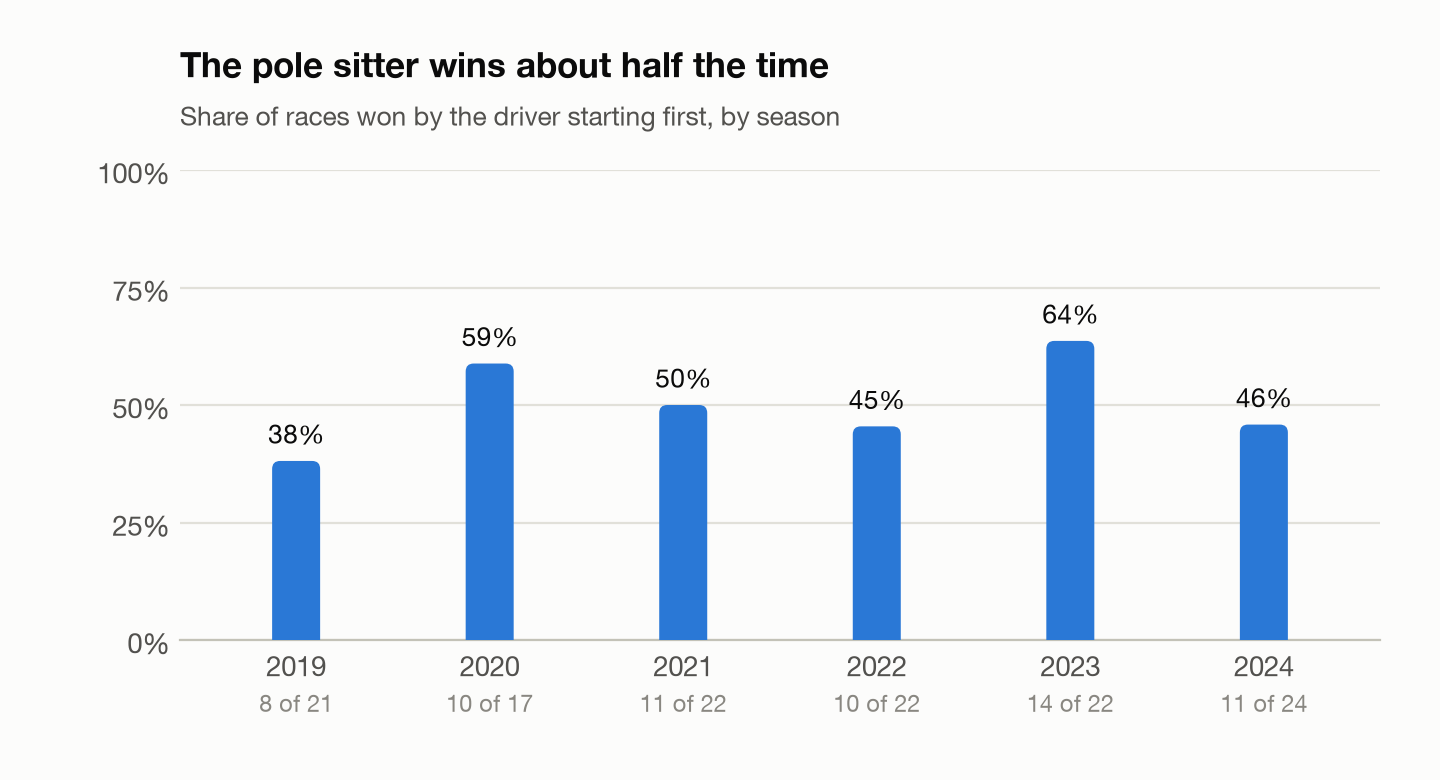

season,races,pole_wins,rate
2019,21,8,38%
2020,17,10,59%
2021,22,11,50%
2022,22,10,45%
2023,22,14,64%
2024,24,11,46%


In [2]:
by_season = eda.pole_by_season(df)
plots.save(plots.pole_conversion_by_season(by_season), "pole_conversion_by_season.png")
display(plots.show(plots.pole_conversion_by_season(by_season)))
display(by_season.style.format({"rate": "{:.0%}"}).hide(axis="index"))

In [3]:
wins, n = int(by_season["pole_wins"].sum()), int(by_season["races"].sum())
low, high = by_season.loc[by_season["rate"].idxmin()], by_season.loc[by_season["rate"].idxmax()]
Markdown(f"**Finding.** The pole sitter won {wins} of {n} races ({wins / n:.0%}), but the rate swings "
         f"from {low['rate']:.0%} in {int(low['season'])} to {high['rate']:.0%} in {int(high['season'])}. "
         f"A season like {int(high['season'])} is hard to beat; the baseline has to be reported for the "
         f"same races as the model, never as a long-run average.")

**Finding.** The pole sitter won 64 of 128 races (50%), but the rate swings from 38% in 2019 to 64% in 2023. A season like 2023 is hard to beat; the baseline has to be reported for the same races as the model, never as a long-run average.

## 2. Win rate by starting position

How much does the grid alone explain?

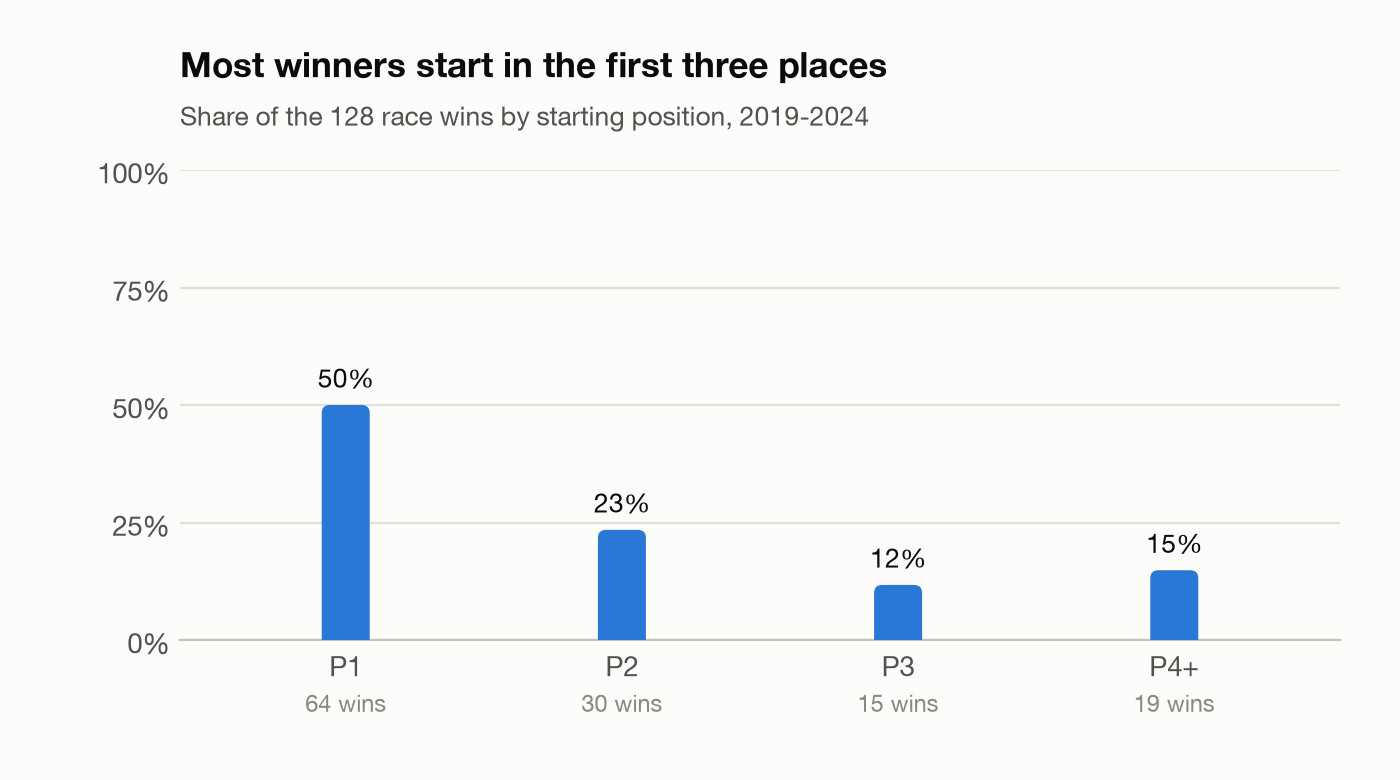

In [4]:
slots = eda.wins_by_grid_slot(df)
display(plots.show(plots.share_bars(
    slots["start"].tolist(), slots["share"].tolist(), [f"{w} wins" for w in slots["wins"]],
    "Most winners start in the first three places",
    f"Share of the {int(slots['wins'].sum())} race wins by starting position, 2019-2024")))

In [5]:
top3 = slots.loc[slots["start"] != "P4+", "share"].sum()
back = slots.loc[slots["start"] == "P4+"].iloc[0]
Markdown(f"**Finding.** {top3:.0%} of winners started in the top three and only {int(back['wins'])} of "
         f"{int(slots['wins'].sum())} started fourth or lower. Grid position is the dominant feature, "
         f"so the model's job is the minority of races the front row does not settle.")

**Finding.** 85% of winners started in the top three and only 19 of 128 started fourth or lower. Grid position is the dominant feature, so the model's job is the minority of races the front row does not settle.

## 3. Pole conversion by circuit

Monaco and Monza behave differently. Is the spread large enough to justify a circuit feature?

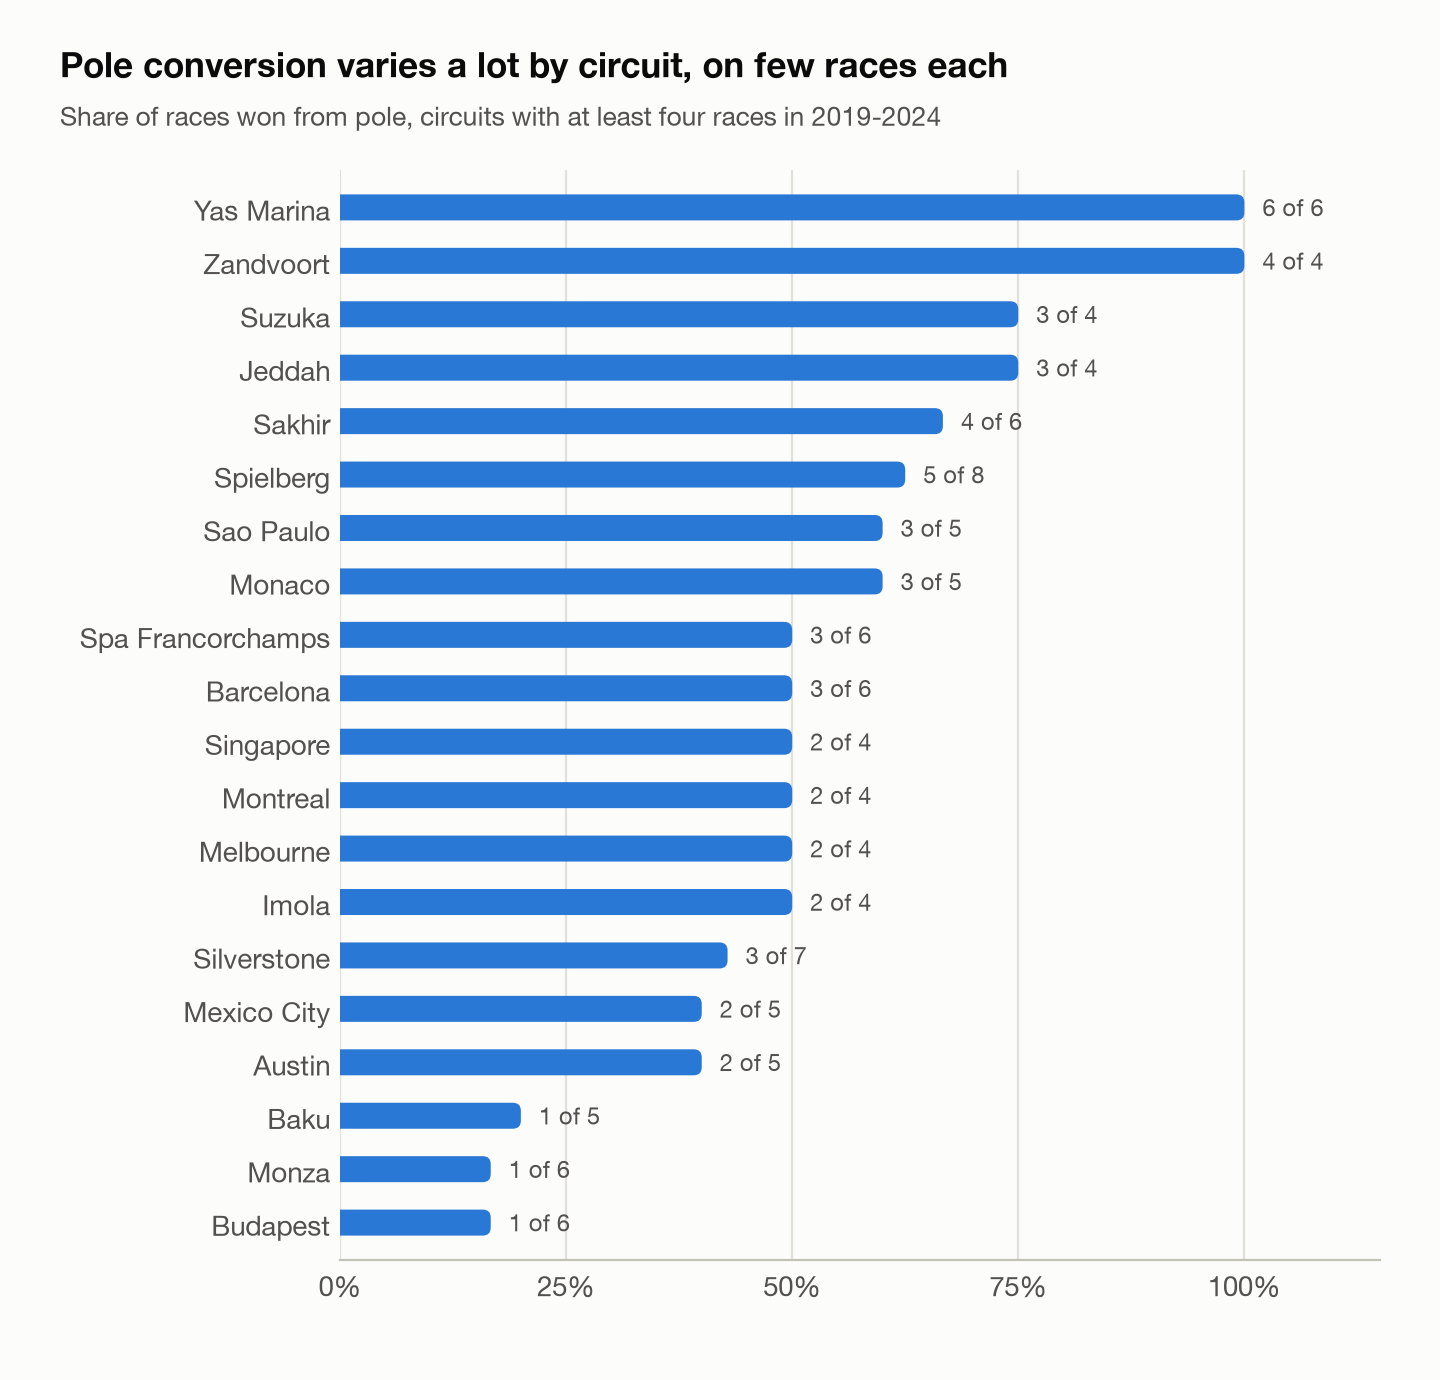

In [6]:
by_circuit = eda.pole_by_circuit(df, min_races=4)
display(plots.show(plots.circuit_bars(
    by_circuit, "Pole conversion varies a lot by circuit, on few races each",
    "Share of races won from pole, circuits with at least four races in 2019-2024")))

In [7]:
top, bottom = by_circuit[by_circuit["rate"] == by_circuit["rate"].max()], by_circuit[by_circuit["rate"] == by_circuit["rate"].min()]
names = lambda t: " and ".join(t["circuit"].str.replace("_", " ").str.title())
kind = by_circuit.groupby("street")[["pole_wins", "races"]].sum()
street, permanent = (kind.loc[k, "pole_wins"] / kind.loc[k, "races"] for k in (1, 0))
Markdown(f"**Finding.** Conversion runs from {bottom['rate'].iloc[0]:.0%} at {names(bottom)} to "
         f"{top['rate'].iloc[0]:.0%} at {names(top)}. That spread justifies `track_pole_win_rate`, but each "
         f"circuit has only {int(by_circuit['races'].min())}-{int(by_circuit['races'].max())} races, so the "
         f"feature is noisy. Street circuits as a group convert {street:.0%} against {permanent:.0%} for "
         f"permanent tracks, so `street_circuit` is unlikely to add much on its own.")

**Finding.** Conversion runs from 17% at Budapest and Monza to 100% at Yas Marina and Zandvoort. That spread justifies `track_pole_win_rate`, but each circuit has only 4-8 races, so the feature is noisy. Street circuits as a group convert 50% against 54% for permanent tracks, so `street_circuit` is unlikely to add much on its own.

## 4. Practice pace versus grid

In races the pole sitter didn't win, how often was the winner fastest on long runs? This is the case for practice features.

races,n,winner had a long run,winner fastest on long runs,share (of winners with a run),median winner gap %
all races,122,102,21,21%,2.06
pole won,60,52,9,17%,2.32
pole lost,62,50,12,24%,1.34


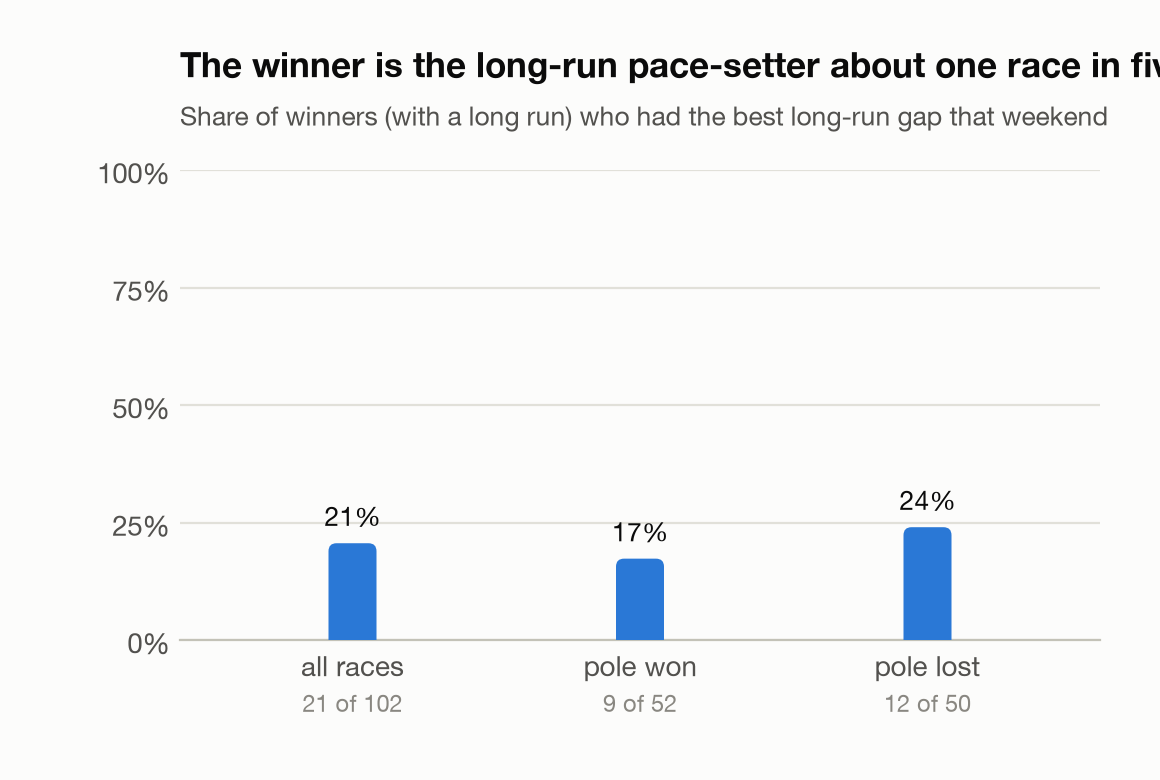

In [8]:
practice = eda.practice_vs_grid(df)
display(practice.style.format({"share (of winners with a run)": "{:.0%}", "median winner gap %": "{:.2f}"}).hide(axis="index"))
display(plots.show(plots.share_bars(
    practice["races"].tolist(), practice["share (of winners with a run)"].tolist(),
    [f"{k} of {m}" for k, m in zip(practice["winner fastest on long runs"], practice["winner had a long run"])],
    "The winner is the long-run pace-setter about one race in five",
    "Share of winners (with a long run) who had the best long-run gap that weekend")))

In [9]:
lost = practice[practice["races"] == "pole lost"].iloc[0]
won = practice[practice["races"] == "pole won"].iloc[0]
field = races.loc[races["drivers_with_longrun"] >= 3, "drivers_with_longrun"].mean()
Markdown(f"**Finding.** In the {int(lost['n'])} races pole lost, the winner was the fastest long-run driver "
         f"{int(lost['winner fastest on long runs'])} times out of {int(lost['winner had a long run'])} "
         f"({lost['share (of winners with a run)']:.0%}); picking at random among the {field:.0f} drivers with a "
         f"long-run time would manage about {1 / field:.0%}. Winners of those races sat a median "
         f"{lost['median winner gap %']:.1f}% off the best long run, against {won['median winner gap %']:.1f}% "
         f"for pole sitters who won. Long-run pace carries real signal but it is noisy: fuel loads and "
         f"run plans differ, so it should refine the grid, not replace it.")

**Finding.** In the 62 races pole lost, the winner was the fastest long-run driver 12 times out of 50 (24%); picking at random among the 17 drivers with a long-run time would manage about 6%. Winners of those races sat a median 1.3% off the best long run, against 2.3% for pole sitters who won. Long-run pace carries real signal but it is noisy: fuel loads and run plans differ, so it should refine the grid, not replace it.

## 5. Form versus grid

How often did the winner come from the team with the best last-five-race form?

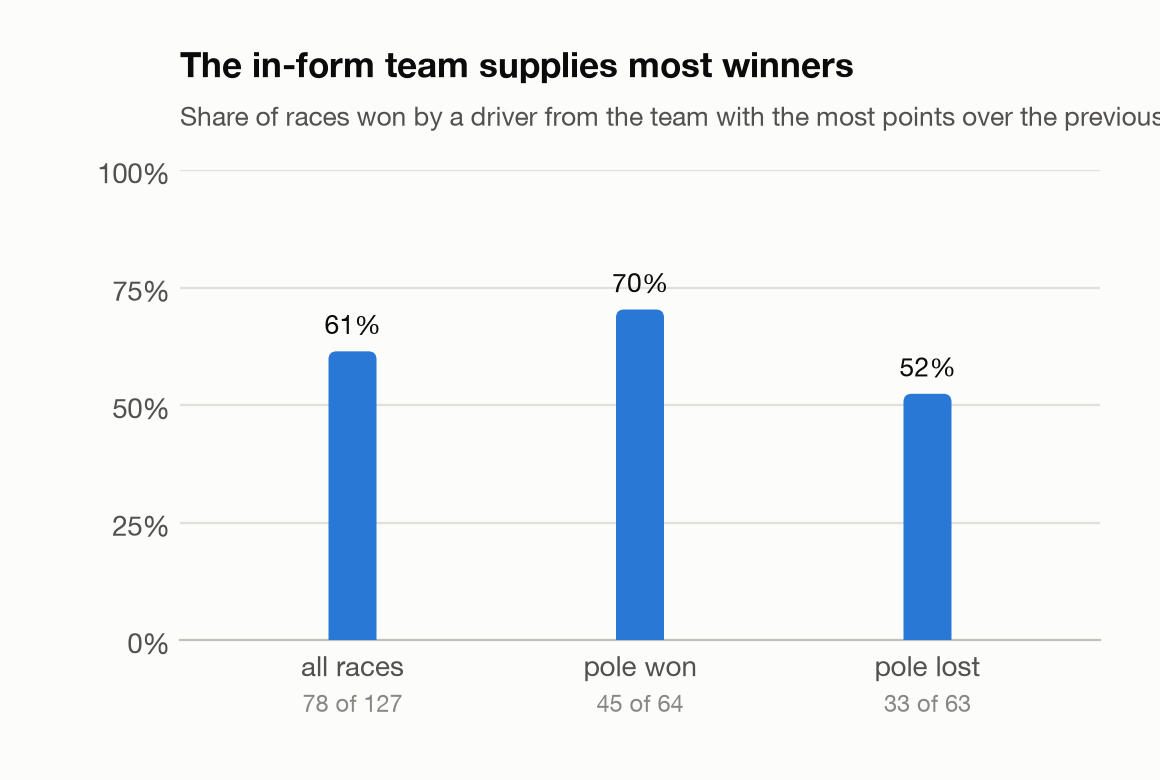

In [10]:
form = eda.form_vs_grid(df)
display(plots.show(plots.share_bars(
    form["races"].tolist(), form["share"].tolist(),
    [f"{k} of {n}" for k, n in zip(form["winner from best-form team"], form["n"])],
    "The in-form team supplies most winners",
    "Share of races won by a driver from the team with the most points over the previous five races")))

In [11]:
every, lost = form[form["races"] == "all races"].iloc[0], form[form["races"] == "pole lost"].iloc[0]
Markdown(f"**Finding.** The winner drove for the best-form team in {int(every['winner from best-form team'])} of "
         f"{int(every['n'])} races ({every['share']:.0%}), and still in {lost['share']:.0%} of the races pole "
         f"lost. Team form points to the right car about half the time even when the grid does not, which "
         f"is the case for the form features.")

**Finding.** The winner drove for the best-form team in 78 of 127 races (61%), and still in 52% of the races pole lost. Team form points to the right car about half the time even when the grid does not, which is the case for the form features.

## 6. Missing-data map

Which weekends lack practice laps, and which drivers have no long run? Their handling is decided here, before feature engineering.

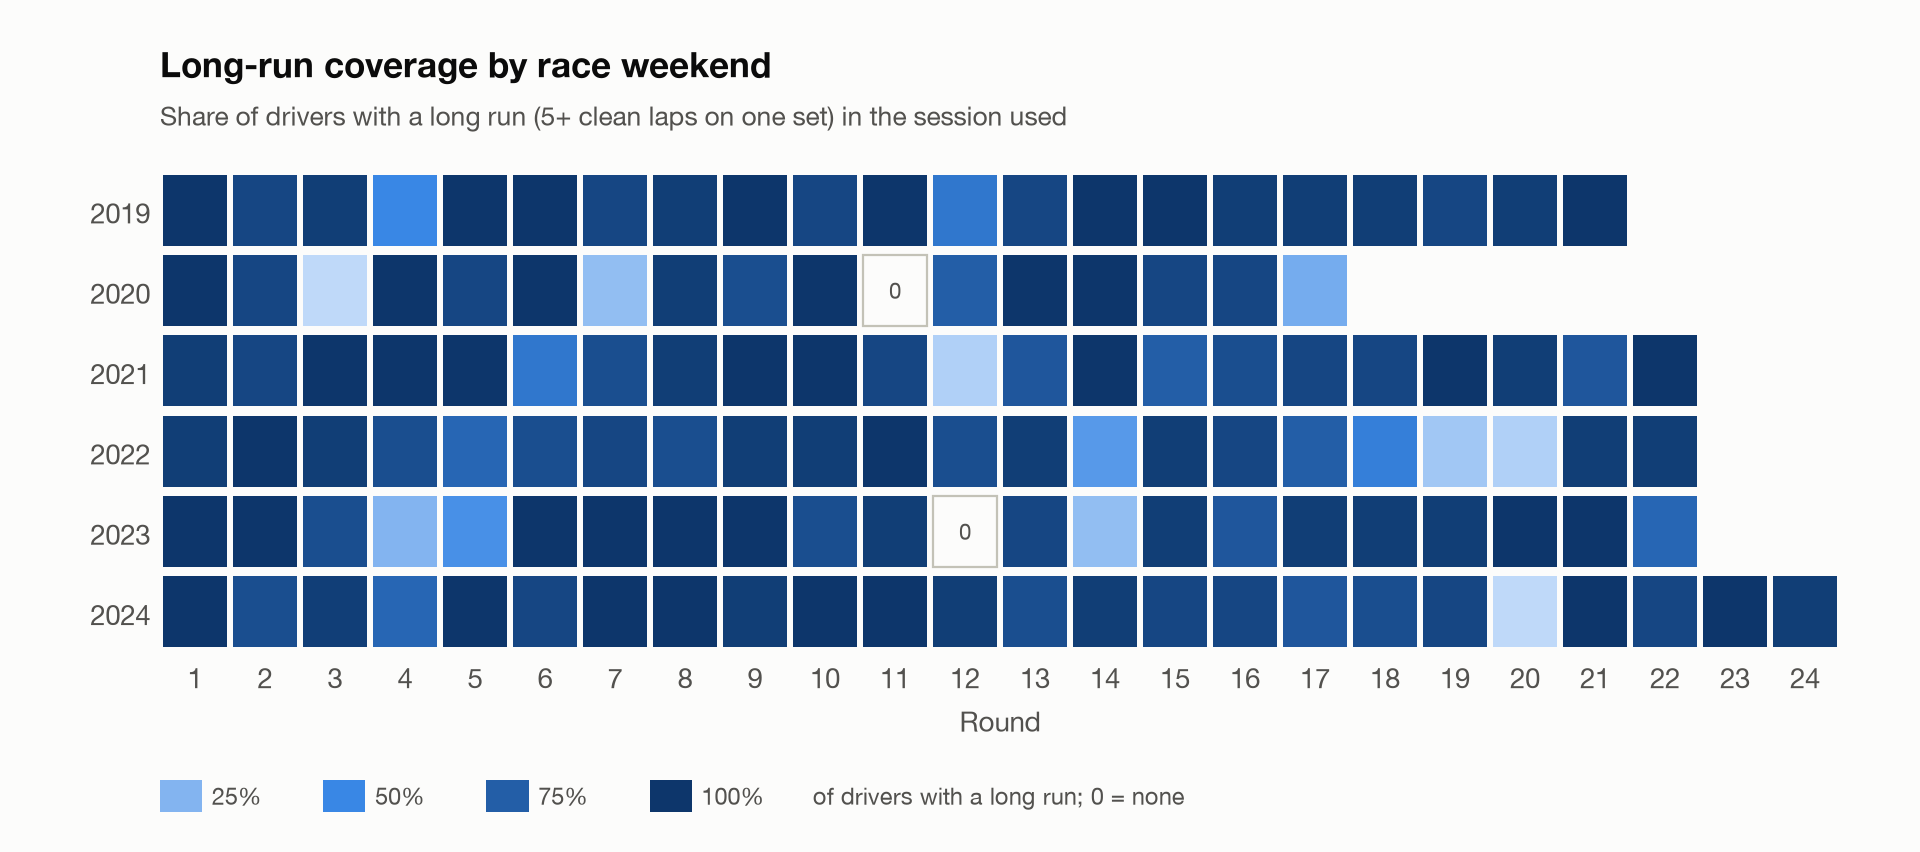

season,races,sprint_weekends,no_practice_laps,no_long_runs,drivers with a long run,drivers with a long-run gap
2019,21,0,0,0,92%,92%
2020,17,0,0,1,75%,72%
2021,22,3,0,0,87%,85%
2022,22,3,0,0,79%,77%
2023,22,6,0,1,81%,79%
2024,24,6,0,0,89%,86%


season,round,event,format,with_short_run
2020,11,Eifel Grand Prix,conventional,19
2023,12,Belgian Grand Prix,sprint_shootout,15


In [12]:
by_year, no_runs = eda.missing_data(df)
coverage = (df.groupby(["season", "round"])["has_longrun"].mean().unstack("round"))
display(plots.show(plots.coverage_map(
    coverage, "Long-run coverage by race weekend",
    "Share of drivers with a long run (5+ clean laps on one set) in the session used")))
display(by_year.style.format({"drivers with a long run": "{:.0%}", "drivers with a long-run gap": "{:.0%}"}).hide(axis="index"))
display(no_runs.style.hide(axis="index"))

In [13]:
none = 1 - df.groupby("format")["has_longrun"].mean()
sprint_formats = none.drop("conventional")
listed = "; ".join(f"{r.season} {r.event}" for r in no_runs.itertuples())
no_laps = int(by_year["no_practice_laps"].sum())
Markdown(f"**Finding.** {no_laps} weekends have no practice laps at all, but {len(no_runs)} have no long run "
         f"({listed}) and {1 - df['has_longrun'].mean():.0%} of all driver-weekends have none: "
         f"{none['conventional']:.0%} on conventional weekends and between {sprint_formats.min():.0%} and "
         f"{sprint_formats.max():.0%} on sprint weekends, depending on that year's sprint format. "
         f"**Handling:** leave `longrun_gap_pct` empty (XGBoost handles missing values natively), add "
         f"`has_longrun` so the model knows why, and fall back from FP2 to FP1 when a weekend has no FP2 "
         f"long runs.")

**Finding.** 0 weekends have no practice laps at all, but 2 have no long run (2020 Eifel Grand Prix; 2023 Belgian Grand Prix) and 16% of all driver-weekends have none: 16% on conventional weekends and between 3% and 31% on sprint weekends, depending on that year's sprint format. **Handling:** leave `longrun_gap_pct` empty (XGBoost handles missing values natively), add `has_longrun` so the model knows why, and fall back from FP2 to FP1 when a weekend has no FP2 long runs.

## What this means for the features

- **Grid first.** Half of all races go to the pole sitter and most of the rest to the front two rows, so `grid_pos` and the qualifying gap are the backbone, and the pole-sitter baseline is the bar.
- **Practice and form are the candidates for added value.** Both point to the winner more often than chance in the races pole loses, and both are noisy.
- **Circuit effects exist but rest on four to eight races each**, so they go in as light features (`track_pole_win_rate`, `drv_track_avg_finish`).
- **Missing practice data is routine, not an error**: about one driver-weekend in six has no long run, so empty values plus a `has_longrun` flag.